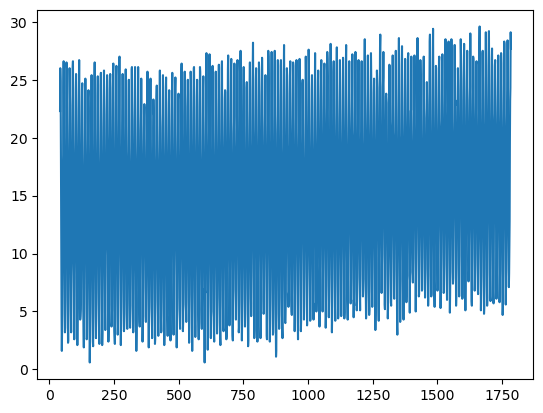

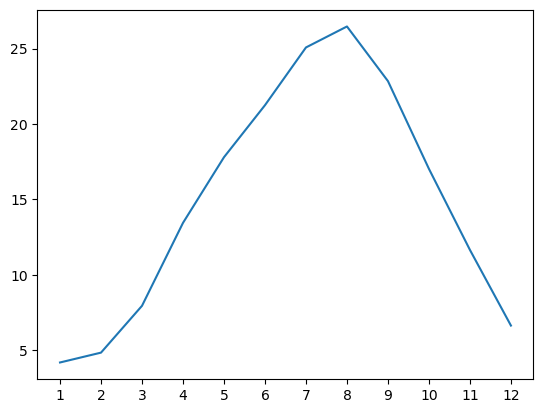

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

A = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9], [10, 11, 12]])
B = np.mean(A, 0) # 0的时候算出每一列的平均值
C = np.mean(A, 1) # 1的时候算出每一行的平均值

# genfromtxt将csv文件读入，然后将里面的数据转化成二维Numpy数组
tokyo_temp = np.genfromtxt("Tokyo_temp.csv", # 指定要读取的文件名字
                           delimiter=",", # 声明文件内容上通过逗号分隔的，csv文件一般都用这种形式
                           usecols=(0, 1, 2) # 只读取数据表中的第1，2，3列。第一列是年，第二列是月，第三列是这个月的平均气温
                          )

y = tokyo_temp[:, 0]
m = tokyo_temp[:, 1]
temp = tokyo_temp[:, 2]

plt.plot(temp)
plt.show()

month = np.arange(1, 13, 1) # 生成12个月
temp_clim = np.zeros(12) # 生成一个行列，用np.zeros初始化为0
for mm in range(1, 13):
    temp_clim[mm-1] = np.nanmean(temp[m==mm]) # nanmean去掉nan空缺值忽略不计。每次只算当前要求的月份的平均值
    # 也可以写成 temp[tokyo_temp[:,1]==mm, 2],等价于temp[m==mm]

plt.plot(month, temp_clim)
plt.xticks(month)
plt.show()

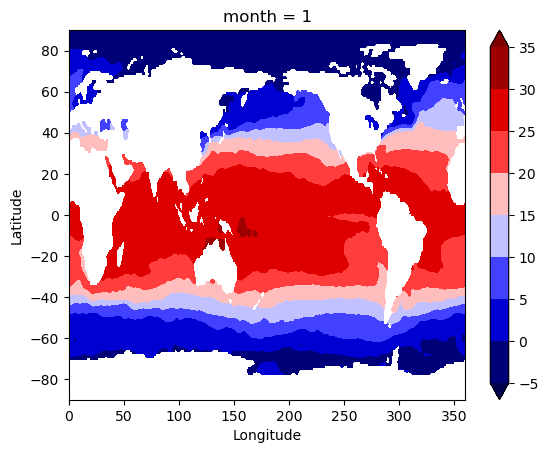

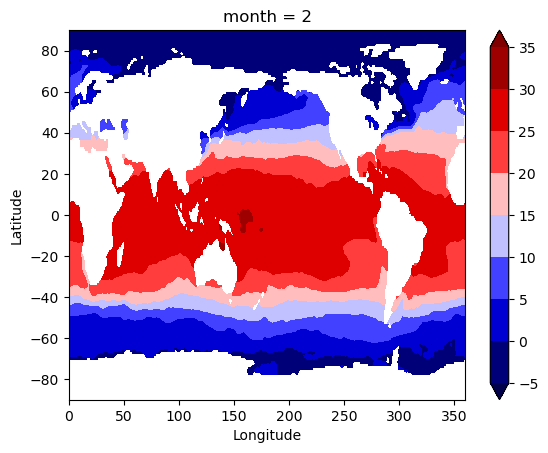

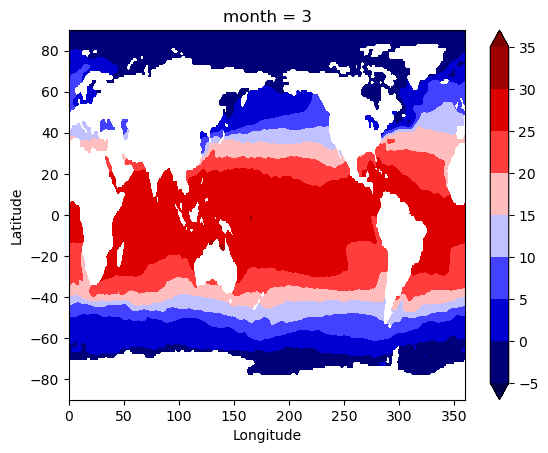

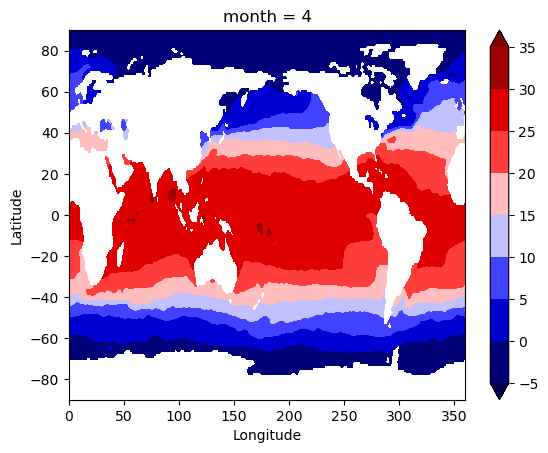

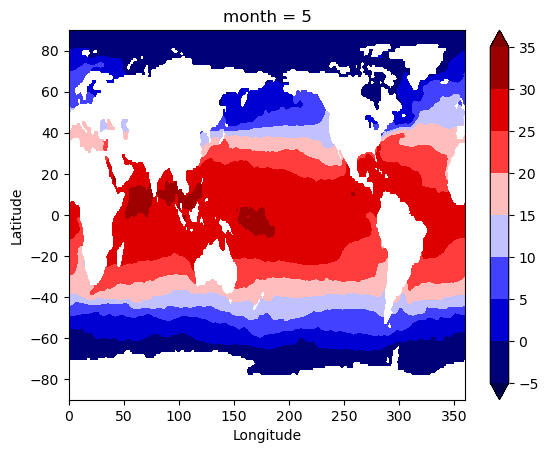

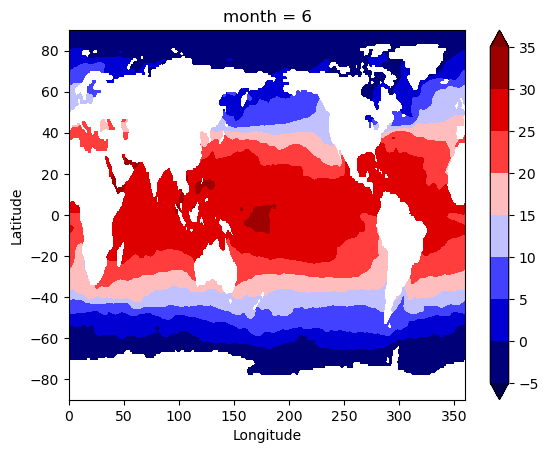

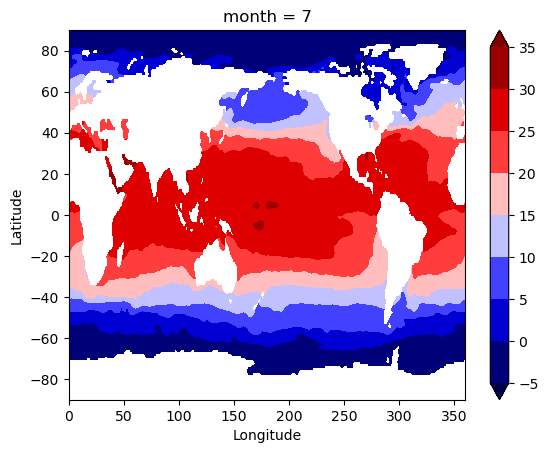

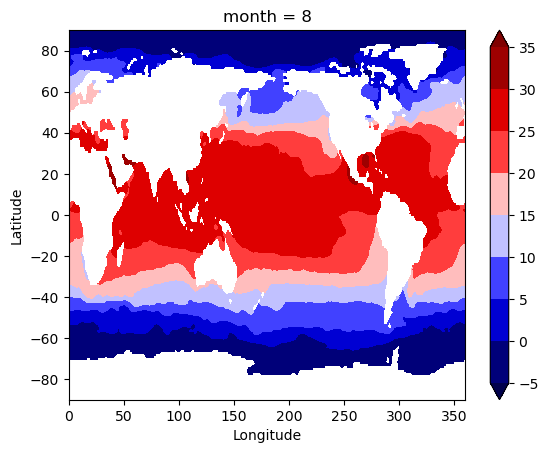

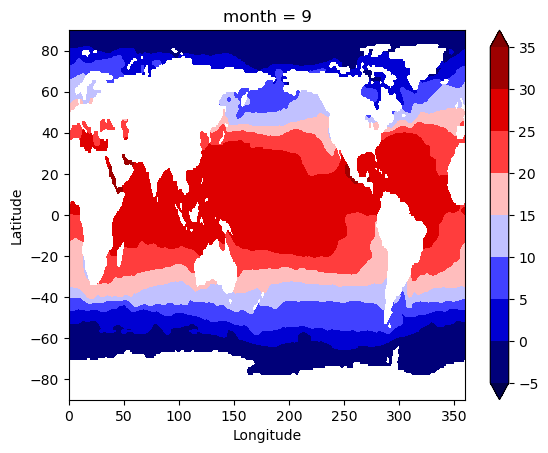

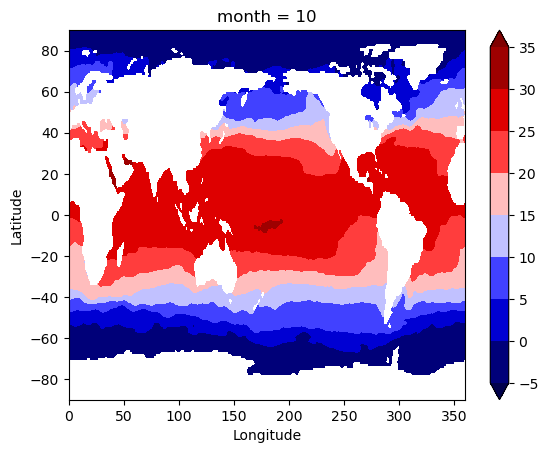

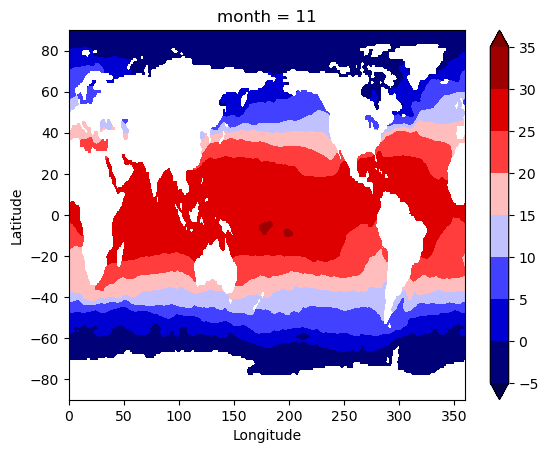

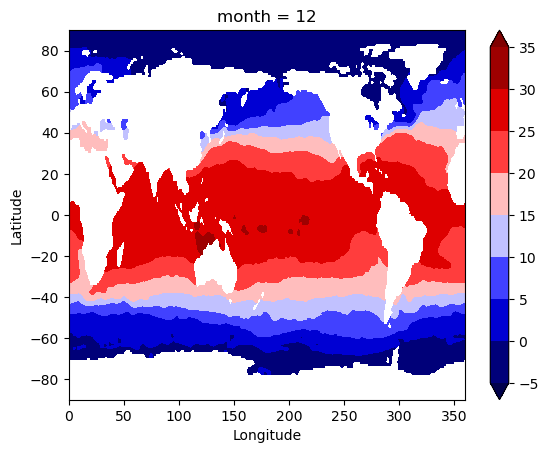

In [22]:
import numpy as np
import matplotlib.pyplot as plt

loadfile = 'sst_OISST.npz'
sst_dataset = np.load(loadfile)

lon2 = sst_dataset['lon2']
lat2 = sst_dataset['lat2']
sst = sst_dataset['sst'] #海面气温
y = sst_dataset['y']
m = sst_dataset['m']

[imt, jmt, tmt] = sst.shape # 读取sst的3维矩阵形状，并将里面的值依次赋值给imt,jmt,tmt
sst_clim = np.zeros((imt, jmt, 12)) # 初始化为0

for mm in range(1, 13):
    sst_clim[:, :, mm-1] = np.mean(sst[:, :, m==mm], 2)

savefile = 'sstc_OISST.npz'
np.savez(savefile, sst_cilm=sst_cilm, lon2=lon2, lat2=lat2)

vmin = -5
vmax = 35
vint = 5

for mm in range(1, 13):
    cm = plt.get_cmap('seismic')
    cs = plt.contourf(lon2, lat2, sst[:, :, mm-1], cmap=cm, norm=Normalize(vmin=vmin, vmax=vmax), levels=np.arange(vmin,vmax+vint,vint), extend='both')
    plt.colorbar(cs)
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    clim_title = 'month = ' + str(mm)
    plt.title(clim_title)
    plt.xlim(0, 360)
    plt.ylim(-90, 90)
    plt.show()


